In [9]:
import math
import os
import sys
import time
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append("..")
from src.apriori import run_apriori
from src.fpgrowth import run_fpgrowth
from src.transactions import load_transactions

# True = tes pakai sampel 2024, False = data penuh 2015-2025
USE_SAMPLE = True

if USE_SAMPLE:
    TX_PATH = "../data/sample/tx_author_based_sample.pkl"
    SUFFIX = "_sample"
else:
    TX_PATH = "../data/processed/tx_author_based.pkl"
    SUFFIX = ""

FIGURES_DIR = "../figures"
STATS_OUT_DIR = "../data/results"
os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(STATS_OUT_DIR, exist_ok=True)

# 4 nilai minimum support yang diuji (0.1%, 0.5%, 1%, 2%)
MIN_SUPPORTS = [0.001, 0.005, 0.01, 0.02]

# load transaksi author-based hasil task 3
transactions = load_transactions(TX_PATH)
N = len(transactions)
print(f"Transaksi: {TX_PATH}")
print(f"Jumlah transaksi: {N:,}")

Transaksi: ../data/sample/tx_author_based_sample.pkl
Jumlah transaksi: 458,522


In [10]:
# jalankan apriori dan fp-growth di tiap min support, catat runtime
results = {}
runtimes = []

for ms in MIN_SUPPORTS:
    t0 = time.perf_counter()
    ap = run_apriori(transactions, ms)
    t_ap = time.perf_counter() - t0

    t0 = time.perf_counter()
    fp = run_fpgrowth(transactions, ms)
    t_fp = time.perf_counter() - t0

    # kedua algoritma harus menghasilkan itemset dan support count yang sama
    assert ap == fp, f"Hasil Apriori dan FP-Growth berbeda pada min_support={ms}"
    results[ms] = ap
    runtimes.append({"min_support": ms, "apriori_s": round(t_ap, 3), "fpgrowth_s": round(t_fp, 3)})
    print(f"min_support={ms:<6} | itemset={len(ap):>6,} | apriori={t_ap:7.2f}s | fp-growth={t_fp:7.2f}s | identik")

min_support=0.001  | itemset=   445 | apriori=   0.63s | fp-growth=   1.06s | identik
min_support=0.005  | itemset=    58 | apriori=   0.44s | fp-growth=   0.57s | identik
min_support=0.01   | itemset=    21 | apriori=   0.39s | fp-growth=   0.61s | identik
min_support=0.02   | itemset=     8 | apriori=   0.38s | fp-growth=   0.51s | identik


In [11]:
# ubah dict{frozenset: support_count} jadi tabel dengan support dalam persen
def itemsets_to_df(itemsets: dict, n: int) -> pd.DataFrame:
    df = pd.DataFrame({
        "itemset": [", ".join(sorted(s)) for s in itemsets],
        "k": [len(s) for s in itemsets],
        "support_count": list(itemsets.values()),
    })
    df["support (%)"] = (df["support_count"] / n * 100).round(3)
    return df.sort_values(["support_count", "itemset"], ascending=[False, True]).reset_index(drop=True)

itemset_dfs = {ms: itemsets_to_df(res, N) for ms, res in results.items()}

# simpan seluruh frequent itemset per min support
for ms, df_ms in itemset_dfs.items():
    df_ms.to_csv(f"{STATS_OUT_DIR}/task4_itemsets_minsup_{ms}{SUFFIX}.csv", index=False)

In [12]:
# jumlah frequent itemset per ukuran k untuk tiap min support
count_rows = []
for ms, df_ms in itemset_dfs.items():
    by_k = df_ms["k"].value_counts()
    count_rows.append({
        "min_support": ms,
        "min_support_count": math.ceil(ms * N),
        "1-itemset": int(by_k.get(1, 0)),
        "2-itemset": int(by_k.get(2, 0)),
        "3-itemset": int(by_k.get(3, 0)),
        ">=4-itemset": int(by_k[by_k.index >= 4].sum()),
        "total": len(df_ms),
    })

# gabungkan dengan runtime kedua algoritma
summary = pd.DataFrame(count_rows).merge(pd.DataFrame(runtimes), on="min_support")
summary.to_csv(f"{STATS_OUT_DIR}/task4_summary{SUFFIX}.csv", index=False)
summary

,min_support,min_support_count,1-itemset,2-itemset,3-itemset,>=4-itemset,total,apriori_s,fpgrowth_s
0,0.001,459,303,100,40,2,445,0.633,1.063
1,0.005,2293,50,8,0,0,58,0.444,0.575
2,0.010,4586,21,0,0,0,21,0.394,0.607
3,0.020,9171,8,0,0,0,8,0.376,0.511


In [13]:
# frequent 1-, 2-, 3-itemset diambil dari min support terkecil (paling lengkap)
LOWEST = min(MIN_SUPPORTS)
base = itemset_dfs[LOWEST]

for k in [1, 2, 3]:
    print(f"Frequent {k}-itemset (min_support={LOWEST}), top 10 dari {int((base['k'] == k).sum()):,}:")
    display(base[base["k"] == k].head(10).reset_index(drop=True))

Frequent 1-itemset (min_support=0.001), top 10 dari 303:


,itemset,k,support_count,support (%)
0,nips,1,18621,4.061
1,cvpr,1,14289,3.116
2,eccv,1,11930,2.602
3,aaai,1,11368,2.479
4,icml,1,10111,2.205
5,icassp,1,9944,2.169
6,emnlp,1,9889,2.157
7,iclr,1,9720,2.120
8,igarss,1,8977,1.958
9,acl,1,7943,1.732


Frequent 2-itemset (min_support=0.001), top 10 dari 100:


,itemset,k,support_count,support (%)
0,"cvpr, eccv",2,3842,0.838
1,"icml, nips",2,3696,0.806
2,"iclr, nips",2,3544,0.773
3,"cvpr, nips",2,3164,0.690
4,"acl, emnlp",2,2689,0.586
5,"eccv, nips",2,2652,0.578
6,"aaai, nips",2,2621,0.572
7,"iclr, icml",2,2609,0.569
8,"aaai, cvpr",2,1979,0.432
9,"emnlp, nips",2,1909,0.416


Frequent 3-itemset (min_support=0.001), top 10 dari 40:


,itemset,k,support_count,support (%)
0,"iclr, icml, nips",3,1532,0.334
1,"cvpr, eccv, nips",3,1511,0.330
2,"cvpr, iclr, nips",3,944,0.206
3,"aaai, cvpr, eccv",3,925,0.202
4,"aaai, cvpr, nips",3,907,0.198
5,"cvpr, eccv, iclr",3,887,0.193
6,"acl, emnlp, nips",3,871,0.190
7,"aaai, icml, nips",3,846,0.185
8,"eccv, iclr, nips",3,822,0.179
9,"cvpr, icml, nips",3,806,0.176


In [14]:
# top 10 itemset berdasarkan support (semua ukuran)
top10_all = base.head(10)
# top 10 kombinasi venue yang sering muncul bersama (k >= 2)
top10_multi = base[base["k"] >= 2].head(10).reset_index(drop=True)

top10_all.to_csv(f"{STATS_OUT_DIR}/task4_top10_itemsets{SUFFIX}.csv", index=False)
top10_multi.to_csv(f"{STATS_OUT_DIR}/task4_top10_venue_combinations{SUFFIX}.csv", index=False)

print("Top-10 itemset (semua ukuran):")
display(top10_all)
print("Top-10 kombinasi venue (k >= 2):")
display(top10_multi)

Top-10 itemset (semua ukuran):


,itemset,k,support_count,support (%)
0,nips,1,18621,4.061
1,cvpr,1,14289,3.116
2,eccv,1,11930,2.602
3,aaai,1,11368,2.479
4,icml,1,10111,2.205
5,icassp,1,9944,2.169
6,emnlp,1,9889,2.157
7,iclr,1,9720,2.120
8,igarss,1,8977,1.958
9,acl,1,7943,1.732


Top-10 kombinasi venue (k >= 2):


,itemset,k,support_count,support (%)
0,"cvpr, eccv",2,3842,0.838
1,"icml, nips",2,3696,0.806
2,"iclr, nips",2,3544,0.773
3,"cvpr, nips",2,3164,0.690
4,"acl, emnlp",2,2689,0.586
5,"eccv, nips",2,2652,0.578
6,"aaai, nips",2,2621,0.572
7,"iclr, icml",2,2609,0.569
8,"aaai, cvpr",2,1979,0.432
9,"emnlp, nips",2,1909,0.416


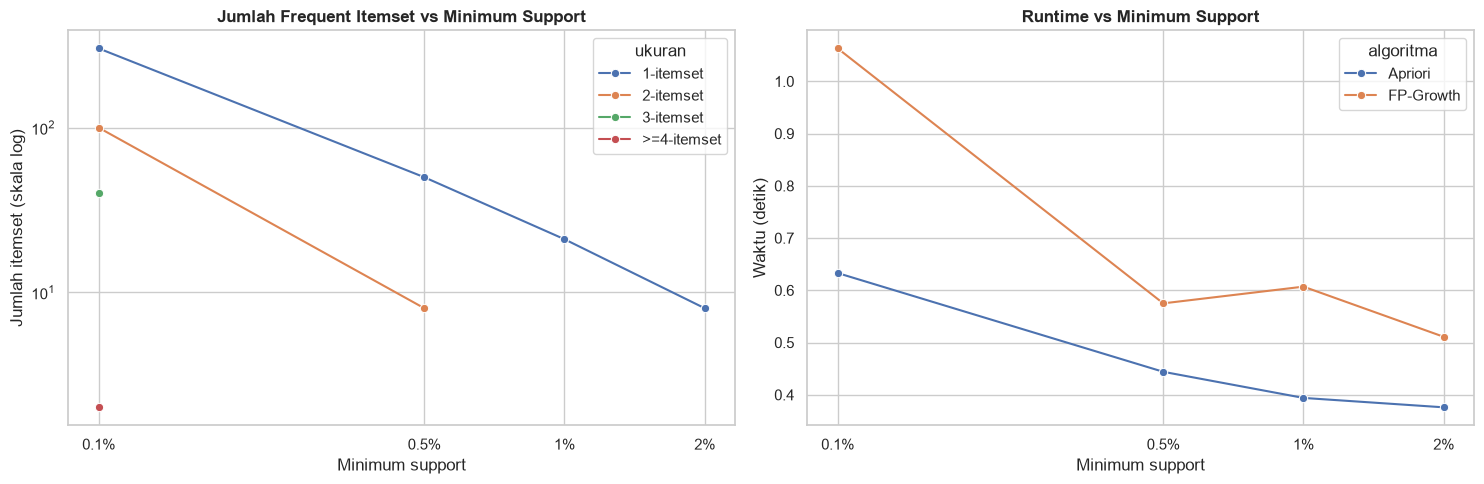

In [15]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# plot 1: pengaruh min support terhadap jumlah frequent itemset
plot_counts = summary.melt(
    id_vars="min_support",
    value_vars=["1-itemset", "2-itemset", "3-itemset", ">=4-itemset"],
    var_name="ukuran", value_name="jumlah",
)
plot_counts = plot_counts[plot_counts["jumlah"] > 0]
sns.lineplot(data=plot_counts, x="min_support", y="jumlah", hue="ukuran", marker="o", ax=axes[0])
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_xticks(MIN_SUPPORTS)
axes[0].set_xticklabels([f"{ms * 100:g}%" for ms in MIN_SUPPORTS])
axes[0].set_title("Jumlah Frequent Itemset vs Minimum Support", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Minimum support")
axes[0].set_ylabel("Jumlah itemset (skala log)")

# plot 2: pengaruh min support terhadap runtime apriori vs fp-growth
rt = summary.melt(id_vars="min_support", value_vars=["apriori_s", "fpgrowth_s"], var_name="algoritma", value_name="detik")
rt["algoritma"] = rt["algoritma"].map({"apriori_s": "Apriori", "fpgrowth_s": "FP-Growth"})
sns.lineplot(data=rt, x="min_support", y="detik", hue="algoritma", marker="o", ax=axes[1])
axes[1].set_xscale("log")
axes[1].set_xticks(MIN_SUPPORTS)
axes[1].set_xticklabels([f"{ms * 100:g}%" for ms in MIN_SUPPORTS])
axes[1].set_title("Runtime vs Minimum Support", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Minimum support")
axes[1].set_ylabel("Waktu (detik)")

plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/task4_minsup_effect{SUFFIX}.png", dpi=300, bbox_inches="tight")
plt.show()

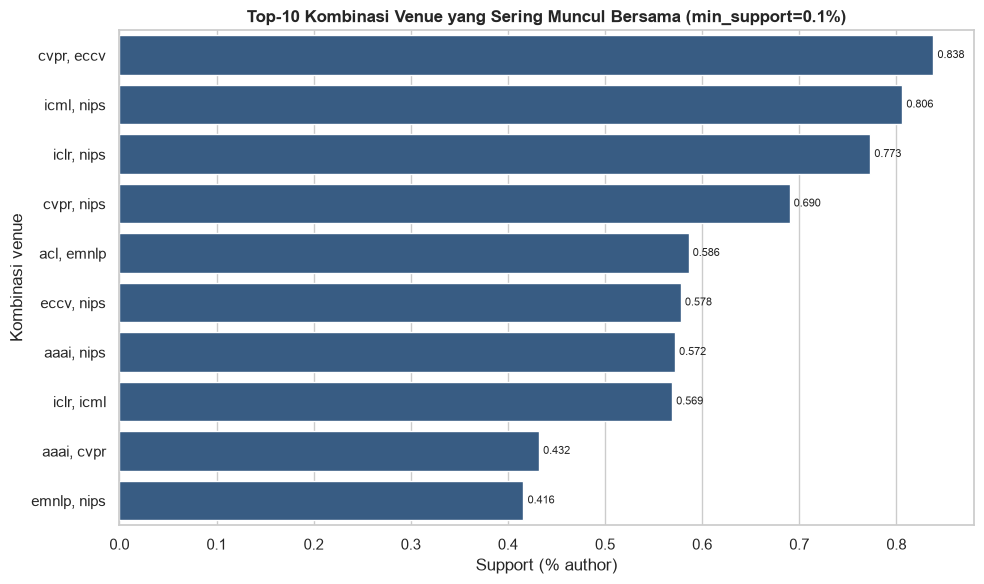

In [16]:
# plot top 10 kombinasi venue berdasarkan support
if len(top10_multi) > 0:
    fig, ax = plt.subplots(figsize=(10, 6))
    sns.barplot(data=top10_multi, y="itemset", x="support (%)", color="#2b5c8f", ax=ax)
    ax.set_title(f"Top-10 Kombinasi Venue yang Sering Muncul Bersama (min_support={LOWEST * 100:g}%)", fontsize=12, fontweight="bold")
    ax.set_xlabel("Support (% author)")
    ax.set_ylabel("Kombinasi venue")
    for container in ax.containers:
        ax.bar_label(container, fmt="%.3f", fontsize=8, padding=3)
    plt.tight_layout()
    plt.savefig(f"{FIGURES_DIR}/task4_top10_venue_combinations{SUFFIX}.png", dpi=300, bbox_inches="tight")
    plt.show()